In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt
import importlib

### other
import mrcfile

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments, distances

### testing
from scipy import integrate
from scipy.stats import norm
from scipy.special import erfinv

In [2]:
# def compute_icdf(N, sigma):
#     # Total mass (upper bound of y)
#     ymax = 2 * np.pi * sigma * np.sqrt(2 * np.pi)
#     # ymax = 1
    
#     # Grid in y (avoid exact 0 and ymax to prevent ±inf)
#     eps = 1e-12
#     y = np.linspace(eps, ymax - eps, N)
    
#     # Normalize to [0,1]
#     u = y / ymax
    
#     # ICDF (quantile function)
#     s = norm.ppf(u)
    
#     return y, s

    
# def compute_icdf_erf(N, sigma):
#     ymax = 2 * np.pi * sigma * np.sqrt(2 * np.pi)
    
#     eps = 1e-12
#     y = np.linspace(eps, ymax - eps, N)
    
#     u = y / ymax
#     s = np.sqrt(2) * erfinv(2 * u - 1)
    
#     return y, s

In [3]:
N = 65
d = 3
sigma = 5

f = utils.gaussian_3d(N, sigma=sigma)
g = utils.gaussian_3d(N, sigma=sigma)

f = signals.Signal(f, d=3, dx=1).preprocess_signals()[0] 
g = signals.Signal(g, d=3, dx=1).preprocess_signals()[0]

print(f.shape)

(65, 65, 65)


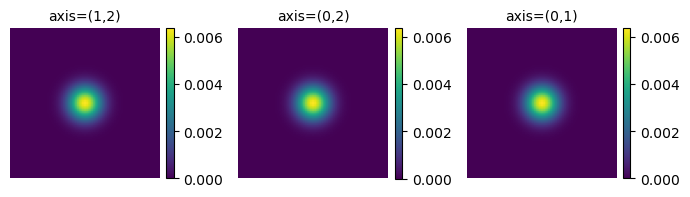

In [4]:
plots.orthogonal_2D_projection_plot(f)

In [5]:
### EV: Note setting normalize=True
###     this shouldn't matter for a centered Gaussian
###     but the RT is not giving \int = 1 as of now

f_rt = transforms.Transform(f, d=3).radon_transform()[0]
f_cdf = transforms.Transform(f, d=3).cdf_transform(normalize=True)[0]
f_icdf = transforms.Transform(f, d=3).inverse_cdf_transform(normalize=True)[0]

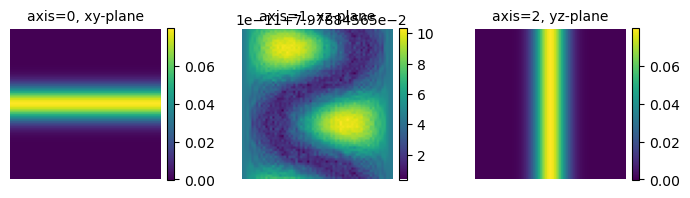

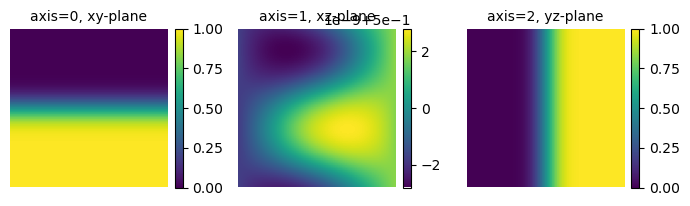

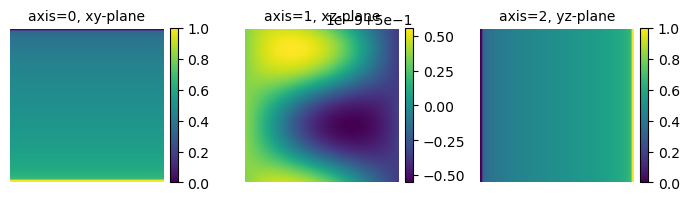

In [6]:
plots.orthogonal_2D_slice_plot(f_rt)
plots.orthogonal_2D_slice_plot(f_cdf)
plots.orthogonal_2D_slice_plot(f_icdf)

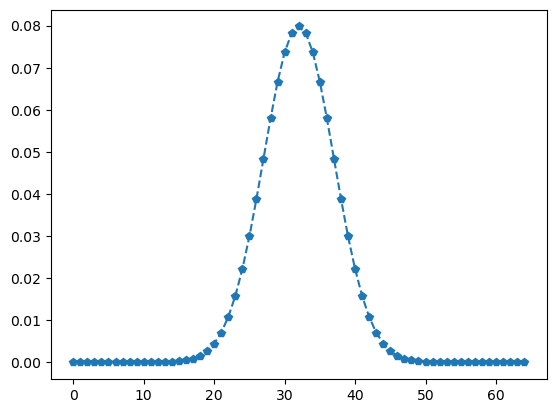

In [7]:
plt.plot(f_rt[0, :, 0], 'p--')

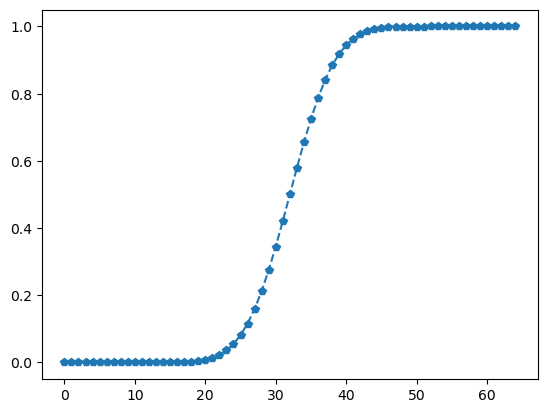

In [8]:
plt.plot(f_cdf[0, :, 0], 'p--')

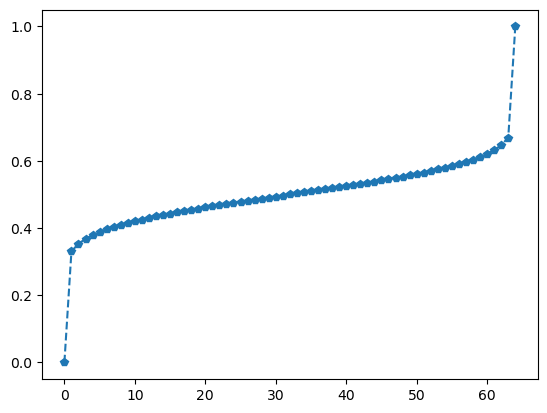

In [9]:
plt.plot(f_icdf[0, :, 0], 'p--')

In [10]:
####

### try different quadrature

### 1) define the grid according to the overleaf
### 2) compute the ICDF using Clenshaw-Curtis
### 3) compare to analytical value

####

In [11]:
### z-grid is defined from [-1, 1], in unit ball

### but we change the notation after doing the Radon transform?
### so that it becomes [0, 1] instead?

### want to compute the ICDF and comparte it to the analytical function

N = 65
sigma = 0.2

# z = np.linspace(-1, 1, N, endpoint=True)
z = np.linspace(-(1 - (1/N)), 1 - (1/N), N, endpoint=True) 
dz = z[1]-z[0]

f = np.exp(- 0.5 * z**2 / (sigma**2))
f = f / (np.sum(f) * dz)

print(np.sum(f))
print(np.sum(f) * dz)

32.5
1.0


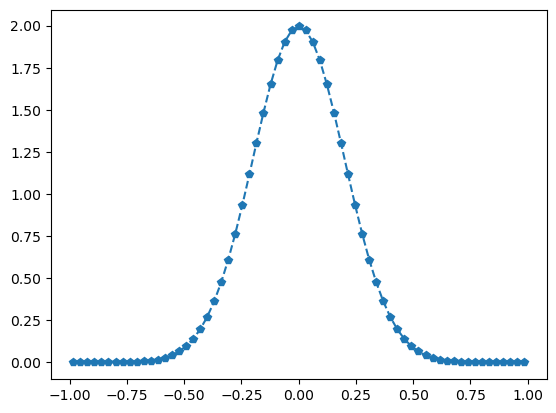

In [12]:
plt.plot(z, f, 'p--')
plt.show()

In [13]:
def cumulative_trapezoid(f, z):
    """returns cumulative integral with cdf[0] = 0"""

    ### include the normalization here?

    dz = z[1:] - z[:-1]
    avg = 0.5 * (f[1:] + f[:-1])
    trap_area = avg * dz
    cdf = np.concatenate([[0], np.cumsum(trap_area)])

    return cdf

In [14]:
### here points are evenly spaced
### but include the grid as an input argument in case it changes later
### how do I define the grid to work with cumulative_trapezoid


# s = np.linspace(-1, 1, N, endpoint=True)

# dx = s[1:] - s[:-1]
# avg = 0.5 * (f[1:] + f[:-1])
# trap_area = avg * dx
# cdf = np.concatenate([[0], np.cumsum(trap_area)])

### EV: still the same as the original grid
# s = np.linspace(-1, 1, N, endpoint=True)

# vf = np.trapz(f, z, dx)
# v = np.cumsum(f)

# vf = np.array([np.trapz(f[:idx], z[:idx], dx) for idx in range(N)])





vf1 = cumulative_trapezoid(f, z)
vf2 = integrate.cumulative_trapezoid(f, z)
vf2 = np.concatenate([[0], vf2])
vf3 = np.cumsum(f)
vf3 = vf3 / vf3[-1]

print(np.allclose(vf1, vf2))

True


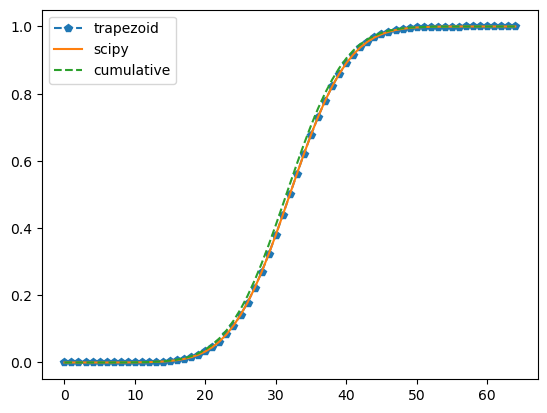

In [15]:

plt.plot(vf1, 'p--', label='trapezoid')
plt.plot(vf2, '-', label='scipy')
plt.plot(vf3, '--', label='cumulative')
plt.legend()

plt.show()

In [16]:
# a = cumulative_trapezoid_explicit(f, z)
# b = integrate.cumulative_trapezoid(f, z)
# c = np.cumsum(f)

# f.shape, a.shape, b.shape, c.shape

# np.allclose(a[1:], b)

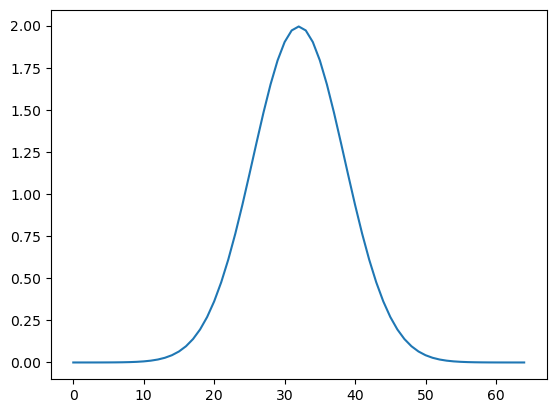

In [17]:
plt.plot(f)

In [18]:
fs = np.ones((N,N))
fs = fs * f[:, np.newaxis]

### lets assume that grid spacing is constant, and can be taken as a single input for now
cdfs = np.zeros(fs.shape)
dz = z[1]-z[0]
avg = 0.5 * (fs[1:, :] + fs[:-1, :])
trap_area = avg * dz
cdfs[1:, :] = np.cumsum(trap_area, axis=0)

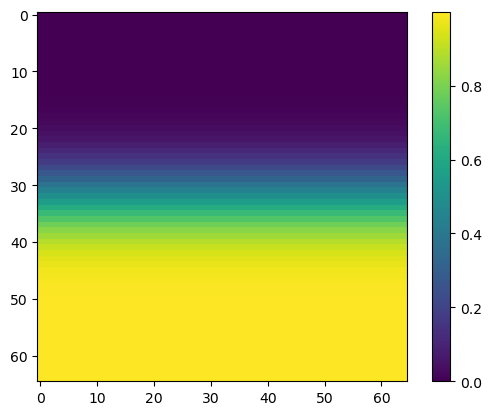

In [19]:
plt.imshow(cdfs)
plt.colorbar()

In [20]:
fs = np.ones((N,N))
fs = fs * f[:, np.newaxis]
fs = fs[np.newaxis, ...]

### lets assume that grid spacing is constant, and can be taken as a single input for now
cdfs = np.zeros(fs.shape)
dz = z[1]-z[0]
avg = 0.5 * (fs[:, 1:, :] + fs[:, :-1, :])
trap_area = avg * dz
cdfs[:, 1:, :] = np.cumsum(trap_area, axis=1)

cdfs = cdfs / cdfs[:, -1, :]

In [21]:
cdfs.shape

(1, 65, 65)

In [22]:
cdfs[0][-1]

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [23]:
dz

0.03076923076923077

In [24]:
n_points = 65

q = np.linspace(-(1 - (1/n_points)), 1 - (1/n_points), n_points, endpoint=True) 

q

array([-0.98461538, -0.95384615, -0.92307692, -0.89230769, -0.86153846,
       -0.83076923, -0.8       , -0.76923077, -0.73846154, -0.70769231,
       -0.67692308, -0.64615385, -0.61538462, -0.58461538, -0.55384615,
       -0.52307692, -0.49230769, -0.46153846, -0.43076923, -0.4       ,
       -0.36923077, -0.33846154, -0.30769231, -0.27692308, -0.24615385,
       -0.21538462, -0.18461538, -0.15384615, -0.12307692, -0.09230769,
       -0.06153846, -0.03076923,  0.        ,  0.03076923,  0.06153846,
        0.09230769,  0.12307692,  0.15384615,  0.18461538,  0.21538462,
        0.24615385,  0.27692308,  0.30769231,  0.33846154,  0.36923077,
        0.4       ,  0.43076923,  0.46153846,  0.49230769,  0.52307692,
        0.55384615,  0.58461538,  0.61538462,  0.64615385,  0.67692308,
        0.70769231,  0.73846154,  0.76923077,  0.8       ,  0.83076923,
        0.86153846,  0.89230769,  0.92307692,  0.95384615,  0.98461538])

In [ ]:
def compute_inverse_cdfs(P, x, u_grid):
    """
    Vectorized computation of inverse CDFs for a matrix P.
    Each column of P is a PDF defined on grid x.
   
    Parameters:
      P      : 2D numpy array of shape (len(x), M), with each column a PDF.
      x      : 1D numpy array of grid points.
      u_grid : 1D numpy array of values in [0,1] for evaluating the inverse CDF.
     
    Returns:
      inv_cdfs: 2D array of shape (len(u_grid), M) where each column is the inverse CDF.
    """
    
    dx = x[1] - x[0]
    # Normalize each column (if not already normalized)
    P_norm = P / (np.sum(P, axis=0) * dx)
    # Compute the CDFs along axis=0 (each column)
    CDF = np.cumsum(P_norm, axis=0) * dx
    # Normalize each column's CDF so that the last entry is 1
    CDF = CDF / CDF[-1, :]
   
    ny, nx = CDF.shape
    cp = u_grid.size
    
    ICDF = np.zeros((cp, nx))
    
    for idx in range(nx):
        # We set bounds_error=False and force fill_value=(x[0], x[-1]) so that u=0,1 map to x[0], x[-1].
        interpolator = interp1d(CDF[:, idx], x, axis=0, bounds_error=False, fill_value=(x[0], x[-1]), assume_sorted=True)
        ICDF[:, idx] = interpolator(u_grid)   
    
    return ICDF



def clenshaw_curtis(n):
    """
    Compute Clenshaw-Curtis nodes and weights for integration on [0,1].
   
    This function first computes Chebyshev nodes on [-1,1] using
       x_i = cos(pi * i/(n-1)), i=0,..., n-1,
    then transforms them to [0,1] via
       u = (1 - x)/2.
    The weights are computed using a standard algorithm.
   
    Parameters:
      n : int, number of nodes (n >= 2)
     
    Returns:
      u : 1D numpy array of nodes in [0,1] (nonuniform, clustering near 0 and 1)
      w : 1D numpy array of quadrature weights (summing to 1)
    """
    
    if n < 2:
        raise ValueError("n must be at least 2")
    k = np.arange(n)
    theta = np.pi * k / (n - 1)
    x_cc = np.cos(theta)       # nodes on [-1,1]
    u = (1 - x_cc) / 2         # transform to [0,1]
   
    w = np.zeros(n)
    if (n - 1) % 2 == 0:
        m = (n - 1) // 2
        for i in range(n):
            s = 0.0
            for j in range(1, m):
                s += 2 * np.cos(2 * j * theta[i]) / (4 * j**2 - 1)
            s += np.cos(2 * m * theta[i]) / (4 * m**2 - 1)
            w[i] = 2 / (n - 1) * (1 - s)
    else:
        m = (n - 1) // 2
        for i in range(n):
            s = 0.0
            for j in range(1, m + 1):
                s += 2 * np.cos(2 * j * theta[i]) / (4 * j**2 - 1)
            w[i] = 2 / (n - 1) * (1 - s)
    # These weights integrate on [-1,1] to 2, so divide by 2 to get integration over [0,1].
    w = w / 2
    
    return u, w



def average_squared_L2_distance_vectorized(P1, P2, x, num_cc=1000):
    """
    Compute the average squared L2 distance between inverse CDFs (quantile functions)
    for corresponding columns of P1 and P2 in a fully vectorized manner.
   
    For each column (each a PDF on grid x), we:
      1. Normalize the PDF.
      2. Compute its inverse CDF on a nonuniform grid u in [0,1] using Clenshaw-Curtis nodes,
         which cluster near 0 and 1 (capturing steep behavior in the tails).
      3. Compute the squared difference between the inverse CDFs for P1 and P2,
         and integrate using the Clenshaw-Curtis quadrature weights.
      4. Average the squared L2 distances over all columns.
   
    Parameters:
      P1, P2 : numpy arrays of shape (len(x), M), where each column is a PDF.
      x      : 1D numpy array of grid points (assumed uniformly spaced).
      num_cc : number of Clenshaw-Curtis nodes (default 1000).
     
    Returns:
      avg_sq_dist : average squared L2 distance between the inverse CDFs.
      col_sq_dist : 1D numpy array (length M) of the squared L2 distances per column.
    """
    
    dx = x[1] - x[0]
    # Get Clenshaw-Curtis nodes and weights on [0,1]
    u_cc, w_cc = clenshaw_curtis(num_cc)  # u_cc: shape (num_cc,), w_cc: shape (num_cc,)
   
    # Compute vectorized inverse CDFs for P1 and P2 (each shape: (num_cc, M))
    inv_cdfs1 = compute_inverse_cdfs(P1, x, u_cc)
    inv_cdfs2 = compute_inverse_cdfs(P2, x, u_cc)
   
    # Compute squared difference (shape: (num_cc, M))
    diff_sq = (inv_cdfs1 - inv_cdfs2) ** 2
    # Integrate along the u-axis using Clenshaw-Curtis weights (broadcast weights to all columns)
    col_sq_dist = np.sum(diff_sq * w_cc[:, np.newaxis], axis=0)
   
    avg_sq_dist = np.sqrt(np.mean(col_sq_dist))
    
    return avg_sq_dist